# Retail Sales Analytics and Revenue Forecasting

## 1. Project Overview

This project analyzes online retail transaction data to understand sales performance, identify business trends, discover top-performing products and countries, and forecast daily revenue using machine learning.

The project uses the Online Retail dataset, which contains invoice numbers, product descriptions, quantities, unit prices, invoice dates, customer IDs, and countries.

Python is used for data analysis and machine learning, while Power BI is used to create an interactive sales dashboard.

## 2. Project Objectives

- Clean and prepare the retail transaction dataset.
- Remove duplicate records and filter cancelled invoices and invalid transactions.
- Calculate revenue for each transaction.
- Analyze key performance indicators (KPIs).
- Identify monthly sales trends and top-performing products, countries, and customers.
- Create charts to understand sales patterns.
- Develop and evaluate machine learning models for daily revenue forecasting.
- Compare models using MAE, RMSE, and R-squared score.
- Build an interactive Power BI dashboard.
- Export analysis results and save the trained model.

## 3. Tools and Technologies

- Python — Data analysis and model development
- Jupyter Notebook — Coding and documentation
- Pandas and NumPy — Data cleaning and calculations
- Matplotlib — Data visualization
- Scikit-learn — Machine learning and model evaluation
- Joblib — Saving and loading the trained model
- Microsoft Power BI — Interactive dashboard
- Microsoft Excel — Source dataset

## 4. Project Workflow

1. Import the required libraries.
2. Load and inspect the dataset.
3. Clean and prepare the transaction data.
4. Calculate transaction revenue and business KPIs.
5. Perform exploratory data analysis (EDA).
6. Analyze monthly revenue, products, countries, and customers.
7. Create visualizations to identify sales patterns.
8. Prepare daily revenue data and forecasting features.
9. Train and evaluate machine learning models.
10. Compare model performance.
11. Generate predictions and analyze forecasting errors.
12. Export results and save the trained model.
13. Present key insights using a Power BI dashboard.

## 5. Machine Learning Approach

The project uses historical daily revenue, previous-day revenue, previous-week revenue, a previous seven-day average, and calendar features to forecast daily revenue.

Linear Regression and Random Forest models are evaluated using a chronological train-test split. Model performance is compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared score.

Forecasts are estimates, not guaranteed sales values. Unusual transactions and changes in sales patterns can affect prediction accuracy.

## 6. Expected Outcome

The project combines data cleaning, sales analysis, visual reporting, and machine learning to demonstrate how Python and Power BI can help businesses understand retail performance and support data-driven decisions.

In [1]:
import os
import pandas as pd

print("Python is working!")
print("Pandas version:", pd.__version__)
print("Current folder:", os.getcwd())
print("Files in folder:", os.listdir())

Python is working!
Pandas version: 2.2.3
Current folder: C:\Users\rajan\OneDrive\Desktop\Retail_Sales_Analytics
Files in folder: ['.ipynb_checkpoints', 'country_sales.csv', 'dashboard', 'data', 'images', 'models', 'monthly_sales.csv', 'outputs', 'README.md', 'reports', 'retail_calendar_model_comparison.csv', 'retail_forecasting_model_comparison.csv', 'retail_kpi_summary.csv', 'retail_ml_model_comparison.csv', 'retail_monthly_analysis.csv', 'retail_next_day_forecast.csv', 'retail_revenue_predictions.csv', 'Retail_Sales_Analytics.ipynb', 'Retail_Sales_Analytics.pbix', 'top_customers.csv', 'top_products.csv']


In [2]:
import pandas as pd

# Load the original dataset
df = pd.read_excel("data/Online Retail.xlsx")

# Create the working dataset
df_original = df.copy(deep=True)
retail = df_original.copy(deep=True)

# Remove duplicate rows
retail = retail.drop_duplicates(
    subset=df_original.columns.tolist()
).copy()

# Prepare columns
retail["InvoiceNo"] = retail["InvoiceNo"].astype("string")
retail["InvoiceDate"] = pd.to_datetime(
    retail["InvoiceDate"],
    errors="coerce"
)

# Identify cancelled invoices
retail["is_cancelled"] = retail["InvoiceNo"].str.startswith(
    "C",
    na=False
)

print("Retail dataset created successfully!")
print("Rows:", len(retail))
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Retail dataset created successfully!
Rows: 536641
Dataset loaded successfully!
Number of rows: 541909
Number of columns: 8


In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Column names:")
print(df.columns.tolist())

Rows: 541909
Columns: 8
Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [6]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [7]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nMissing value percentage:")
print((df.isnull().mean() * 100).round(2))

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Missing value percentage:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [8]:
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

Total duplicate rows: 5268


In [9]:
df[df.duplicated(keep=False)].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [10]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

cancelled = df["InvoiceNo"].str.startswith("C")

print("Cancelled invoice rows:", cancelled.sum())
print("Other invoice rows:", (~cancelled).sum())

Cancelled invoice rows: 9288
Other invoice rows: 532621


In [11]:
print("Zero or negative quantities:",
      (df["Quantity"] <= 0).sum())

print("Zero or negative unit prices:",
      (df["UnitPrice"] <= 0).sum())

Zero or negative quantities: 10624
Zero or negative unit prices: 2517


In [12]:
print("InvoiceDate data type:", df["InvoiceDate"].dtype)

print("Missing CustomerIDs:",
      df["CustomerID"].isnull().sum())

print("Unique products:", df["StockCode"].nunique())

print("Unique customers:", df["CustomerID"].nunique())

print("Unique countries:", df["Country"].nunique())

InvoiceDate data type: datetime64[ns]
Missing CustomerIDs: 135080
Unique products: 4070
Unique customers: 4372
Unique countries: 38


In [13]:
sales = retail[
    (~retail["is_cancelled"])
    & (retail["Quantity"] > 0)
    & (retail["UnitPrice"] > 0)
    & (retail["InvoiceDate"].notna())
].copy()

sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

print("Clean sales rows:", len(sales))
print("Total revenue:", round(sales["Revenue"].sum(), 2))

Clean sales rows: 524878
Total revenue: 10642110.8


In [14]:
# Start again from the untouched original data
retail = df_original.copy(deep=True)

# Remove exact duplicates using only the original 8 columns
original_columns = df_original.columns.tolist()

retail = retail.drop_duplicates(
    subset=original_columns
).copy()

# Convert the invoice number to text for cancellation checks
retail["InvoiceNo"] = retail["InvoiceNo"].astype("string")

# Convert dates safely
retail["InvoiceDate"] = pd.to_datetime(
    retail["InvoiceDate"],
    errors="coerce"
)

print("Original rows:", len(df_original))
print("Rows after correct deduplication:", len(retail))
print("Exact duplicate rows removed:",
      len(df_original) - len(retail))

Original rows: 541909
Rows after correct deduplication: 536641
Exact duplicate rows removed: 5268


In [15]:
retail["is_cancelled"] = (
    retail["InvoiceNo"].str.startswith("C", na=False)
)

sales = retail[
    (~retail["is_cancelled"])
    & (retail["Quantity"] > 0)
    & (retail["UnitPrice"] > 0)
    & (retail["InvoiceDate"].notna())
].copy()

sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

print("Clean sales rows:", len(sales))
print("Total revenue:", round(sales["Revenue"].sum(), 2))
print("Unique invoices:", sales["InvoiceNo"].nunique())
print("Unique customers:", sales["CustomerID"].nunique())

Clean sales rows: 524878
Total revenue: 10642110.8
Unique invoices: 19960
Unique customers: 4338


In [16]:
sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M")

monthly_sales = (
    sales.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

monthly_sales["YearMonth"] = (
    monthly_sales["YearMonth"].astype(str)
)

print(monthly_sales)

   YearMonth      Revenue
0    2010-12   821452.730
1    2011-01   689811.610
2    2011-02   522545.560
3    2011-03   716215.260
4    2011-04   536968.491
5    2011-05   769296.610
6    2011-06   760547.010
7    2011-07   718076.121
8    2011-08   757841.380
9    2011-09  1056435.192
10   2011-10  1151263.730
11   2011-11  1503866.780
12   2011-12   637790.330


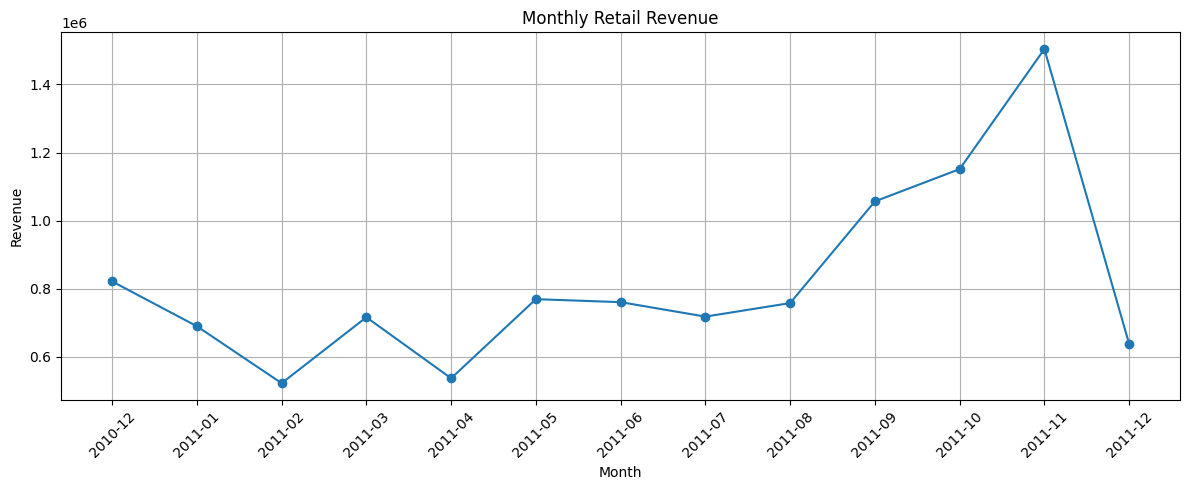

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["YearMonth"],
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Retail Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
top_products = (
    sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


In [19]:
print("Original rows:", len(df_original))
print("Rows after deduplication:", len(retail))
print("Duplicates removed:", len(df_original) - len(retail))

print("\nOrdinary sales rows:", len(sales))
print("Total ordinary-sales revenue:", round(sales["Revenue"].sum(), 2))
print("Unique invoices:", sales["InvoiceNo"].nunique())
print("Unique identified customers:", sales["CustomerID"].nunique())

print("\nDuplicate rows remaining:",
      sales.duplicated(subset=df_original.columns.tolist()).sum())

print("Invalid dates remaining:",
      sales["InvoiceDate"].isna().sum())

Original rows: 541909
Rows after deduplication: 536641
Duplicates removed: 5268

Ordinary sales rows: 524878
Total ordinary-sales revenue: 10642110.8
Unique invoices: 19960
Unique identified customers: 4338

Duplicate rows remaining: 0
Invalid dates remaining: 0


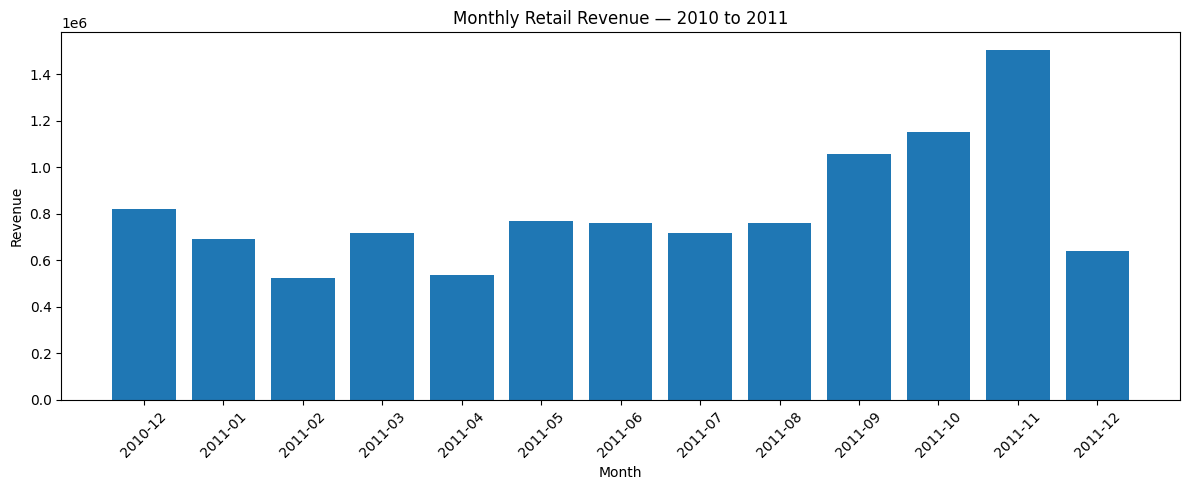

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_sales["YearMonth"],
    monthly_sales["Revenue"]
)

plt.title("Monthly Retail Revenue — 2010 to 2011")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
top_products = (
    sales.groupby("Description", dropna=False)
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Transaction_Lines=("InvoiceNo", "count")
    )
    .sort_values("Total_Revenue", ascending=False)
    .head(10)
)

print(top_products.round(2))

                                    Total_Revenue  Units_Sold  \
Description                                                     
DOTCOM POSTAGE                          206248.77         706   
REGENCY CAKESTAND 3 TIER                174156.54       13851   
PAPER CRAFT , LITTLE BIRDIE             168469.60       80995   
WHITE HANGING HEART T-LIGHT HOLDER      106236.72       37872   
PARTY BUNTING                            99445.23       18283   
JUMBO BAG RED RETROSPOT                  94159.81       48371   
MEDIUM CERAMIC TOP STORAGE JAR           81700.92       78033   
POSTAGE                                  78101.88        3150   
Manual                                   77752.82        6985   
RABBIT NIGHT LIGHT                       66870.03       30739   

                                    Transaction_Lines  
Description                                            
DOTCOM POSTAGE                                    706  
REGENCY CAKESTAND 3 TIER                         20

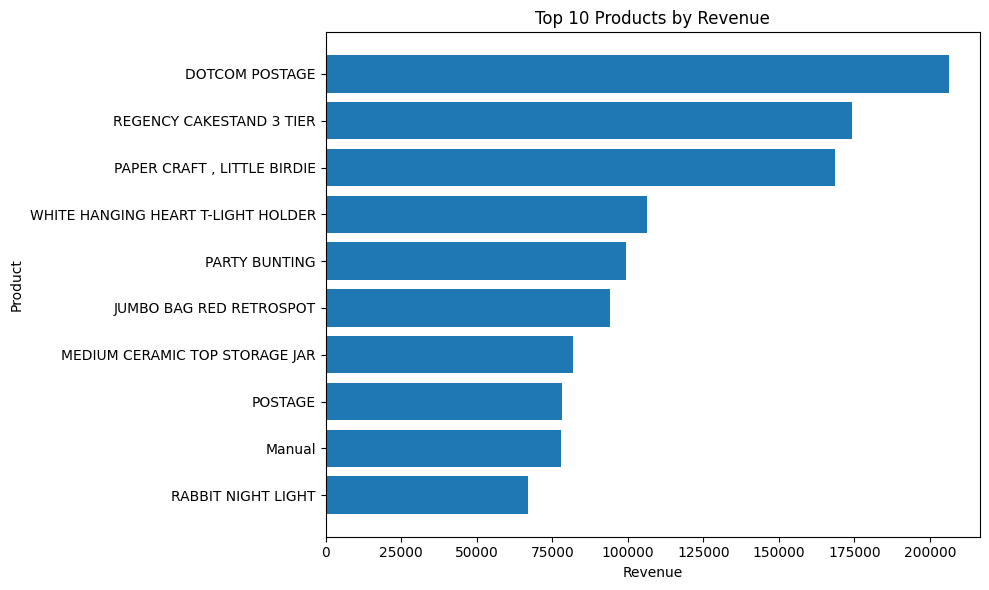

In [22]:
top_products_chart = top_products.sort_values("Total_Revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_products_chart.index.astype(str),
    top_products_chart["Total_Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [23]:
country_sales = (
    sales.groupby("Country")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
)

print(country_sales.head(10).round(2))

                Total_Revenue  Units_Sold  Unique_Invoices
Country                                                   
United Kingdom     9001744.09     4646906            18019
Netherlands         285446.34      200361               94
EIRE                283140.52      147007              288
Germany             228678.40      119154              457
France              209625.37      112060              392
Australia           138453.81       83891               57
Spain                61558.56       27933               90
Switzerland          57067.60       30617               54
Belgium              41196.34       23237               98
Sweden               38367.83       36078               36


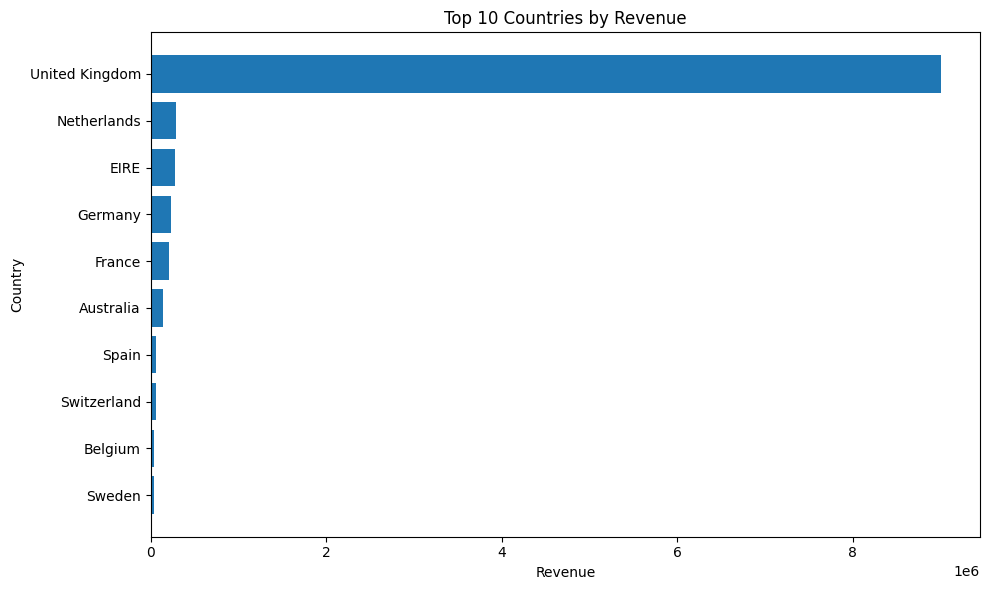

In [24]:
top_countries = country_sales.head(10).sort_values("Total_Revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries.index,
    top_countries["Total_Revenue"]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [25]:
identified_sales = sales.dropna(subset=["CustomerID"]).copy()

top_customers = (
    identified_sales.groupby("CustomerID")
    .agg(
        Total_Spent=("Revenue", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique"),
        Units_Bought=("Quantity", "sum")
    )
    .sort_values("Total_Spent", ascending=False)
    .head(10)
)

print(top_customers.round(2))

            Total_Spent  Unique_Invoices  Units_Bought
CustomerID                                            
14646.0       280206.02               73        196915
18102.0       259657.30               60         64124
17450.0       194390.79               46         69973
16446.0       168472.50                2         80997
14911.0       143711.17              201         80240
12415.0       124914.53               21         77374
14156.0       117210.08               55         57768
17511.0        91062.38               31         64549
16029.0        80850.84               63         40108
12346.0        77183.60                1         74215


In [26]:
monthly_sales.to_csv("monthly_sales.csv", index=False)
top_products.to_csv("top_products.csv")
country_sales.to_csv("country_sales.csv")
top_customers.to_csv("top_customers.csv")

print("Analysis files saved successfully!")

Analysis files saved successfully!


In [27]:
import pandas as pd

total_revenue = sales["Revenue"].sum()
total_units = sales["Quantity"].sum()
total_invoices = sales["InvoiceNo"].nunique()
total_customers = identified_sales["CustomerID"].nunique()
average_invoice_value = total_revenue / total_invoices

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Units Sold",
        "Unique Invoices",
        "Identified Customers",
        "Average Revenue per Invoice"
    ],
    "Value": [
        round(total_revenue, 2),
        int(total_units),
        total_invoices,
        total_customers,
        round(average_invoice_value, 2)
    ]
})

kpi_summary

,KPI,Value
0,Total Revenue,10642110.80
1,Units Sold,5572420.00
2,Unique Invoices,19960.00
3,Identified Customers,4338.00
4,Average Revenue per Invoice,533.17


In [28]:
monthly_analysis = monthly_sales.copy()

monthly_analysis["Revenue_Change"] = (
    monthly_analysis["Revenue"].diff()
)

monthly_analysis["Revenue_Change_Percent"] = (
    monthly_analysis["Revenue"].pct_change() * 100
)

print("Highest revenue month:")
print(monthly_analysis.loc[
    monthly_analysis["Revenue"].idxmax()
])

print("\nLowest revenue month:")
print(monthly_analysis.loc[
    monthly_analysis["Revenue"].idxmin()
])

print("\nMonthly trend:")
print(monthly_analysis.round(2).to_string(index=False))

Highest revenue month:
YearMonth                    2011-11
Revenue                   1503866.78
Revenue_Change             352603.05
Revenue_Change_Percent     30.627478
Name: 11, dtype: object

Lowest revenue month:
YearMonth                   2011-02
Revenue                   522545.56
Revenue_Change           -167266.05
Revenue_Change_Percent   -24.248077
Name: 2, dtype: object

Monthly trend:
YearMonth    Revenue  Revenue_Change  Revenue_Change_Percent
  2010-12  821452.73             NaN                     NaN
  2011-01  689811.61      -131641.12                  -16.03
  2011-02  522545.56      -167266.05                  -24.25
  2011-03  716215.26       193669.70                   37.06
  2011-04  536968.49      -179246.77                  -25.03
  2011-05  769296.61       232328.12                   43.27
  2011-06  760547.01        -8749.60                   -1.14
  2011-07  718076.12       -42470.89                   -5.58
  2011-08  757841.38        39765.26              

In [29]:
top10_product_revenue = top_products["Total_Revenue"].sum()

top10_product_share = (
    top10_product_revenue / total_revenue
) * 100

print("Top 10 product revenue:",
      round(top10_product_revenue, 2))

print("Top 10 product revenue share:",
      round(top10_product_share, 2), "%")

Top 10 product revenue: 1153142.32
Top 10 product revenue share: 10.84 %


In [30]:
top10_country_revenue = country_sales.head(10)[
    "Total_Revenue"
].sum()

top10_country_share = (
    top10_country_revenue / total_revenue
) * 100

print("Top 10 country revenue:",
      round(top10_country_revenue, 2))

print("Top 10 country revenue share:",
      round(top10_country_share, 2), "%")

print("\nTop 5 countries:")
print(country_sales.head(5).round(2))

Top 10 country revenue: 10345278.86
Top 10 country revenue share: 97.21 %

Top 5 countries:
                Total_Revenue  Units_Sold  Unique_Invoices
Country                                                   
United Kingdom     9001744.09     4646906            18019
Netherlands         285446.34      200361               94
EIRE                283140.52      147007              288
Germany             228678.40      119154              457
France              209625.37      112060              392


In [31]:
top10_customer_revenue = top_customers[
    "Total_Spent"
].sum()

top10_customer_share = (
    top10_customer_revenue / total_revenue
) * 100

print("Top 10 customer revenue:",
      round(top10_customer_revenue, 2))

print("Top 10 customer share of total revenue:",
      round(top10_customer_share, 2), "%")

Top 10 customer revenue: 1537659.21
Top 10 customer share of total revenue: 14.45 %


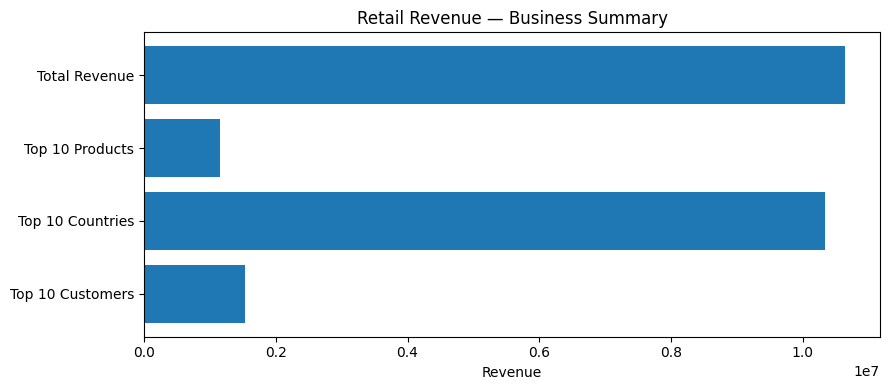

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))

labels = [
    "Total Revenue",
    "Top 10 Products",
    "Top 10 Countries",
    "Top 10 Customers"
]

values = [
    total_revenue,
    top10_product_revenue,
    top10_country_revenue,
    top10_customer_revenue
]

ax.barh(labels, values)
ax.set_title("Retail Revenue — Business Summary")
ax.set_xlabel("Revenue")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [33]:
kpi_summary.to_csv("retail_kpi_summary.csv", index=False)

monthly_analysis.to_csv(
    "retail_monthly_analysis.csv",
    index=False
)

print("KPI summary and monthly analysis exported!")

KPI summary and monthly analysis exported!


In [34]:
print("Sales rows:", len(sales))
print("Columns:", sales.columns.tolist())
print(sales[["InvoiceDate", "Revenue"]].head())

Sales rows: 524878
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'is_cancelled', 'Revenue', 'YearMonth']
          InvoiceDate  Revenue
0 2010-12-01 08:26:00    15.30
1 2010-12-01 08:26:00    20.34
2 2010-12-01 08:26:00    22.00
3 2010-12-01 08:26:00    20.34
4 2010-12-01 08:26:00    20.34


In [35]:
daily_sales = (
    sales
    .set_index("InvoiceDate")["Revenue"]
    .resample("D")
    .sum()
    .rename("Revenue")
    .to_frame()
)

print(daily_sales.head())
print("Number of calendar days:", len(daily_sales))

              Revenue
InvoiceDate          
2010-12-01   58776.79
2010-12-02   47629.42
2010-12-03   46898.63
2010-12-04       0.00
2010-12-05   31364.63
Number of calendar days: 374


In [36]:
daily_sales["Revenue_Lag_1"] = daily_sales["Revenue"].shift(1)

daily_sales["Revenue_Lag_7"] = daily_sales["Revenue"].shift(7)

daily_sales["Previous_7_Day_Average"] = (
    daily_sales["Revenue"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

model_data = daily_sales.dropna().copy()

print(model_data.head())
print("Rows available for modeling:", len(model_data))

              Revenue  Revenue_Lag_1  Revenue_Lag_7  Previous_7_Day_Average
InvoiceDate                                                                
2010-12-08   45235.36       99553.85       58776.79            48406.781429
2010-12-09   53548.19       45235.36       47629.42            46472.291429
2010-12-10   59021.02       53548.19       46898.63            47317.830000
2010-12-11       0.00       59021.02           0.00            49049.600000
2010-12-12   17125.65           0.00       31364.63            49049.600000
Rows available for modeling: 367


In [37]:
features = [
    "Revenue_Lag_1",
    "Revenue_Lag_7",
    "Previous_7_Day_Average"
]

X = model_data[features]
y = model_data["Revenue"]

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("First test date:", y_test.index.min())
print("Last test date:", y_test.index.max())

Training rows: 293
Testing rows: 74
First test date: 2011-09-27 00:00:00
Last test date: 2011-12-09 00:00:00


In [38]:
from sklearn.linear_model import LinearRegression

retail_model = LinearRegression()

retail_model.fit(X_train, y_train)

print("Retail regression model trained!")

Retail regression model trained!


In [39]:
predictions = retail_model.predict(X_test)

results = pd.DataFrame({
    "Actual_Revenue": y_test,
    "Predicted_Revenue": predictions
})

print(results.head(10).round(2))

             Actual_Revenue  Predicted_Revenue
InvoiceDate                                   
2011-09-27         36260.91           71248.14
2011-09-28         43693.08           38925.26
2011-09-29         46343.35           46273.70
2011-09-30         44347.06           36400.08
2011-10-01             0.00           13255.78
2011-10-02         11531.56           22935.32
2011-10-03         66243.94           24082.61
2011-10-04         48652.54           37286.47
2011-10-05         75460.77           38246.44
2011-10-06         62761.92           44155.61


In [40]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R-squared:", round(r2, 3))

Mean Absolute Error: 17207.5
Root Mean Squared Error: 25837.46
R-squared: 0.292


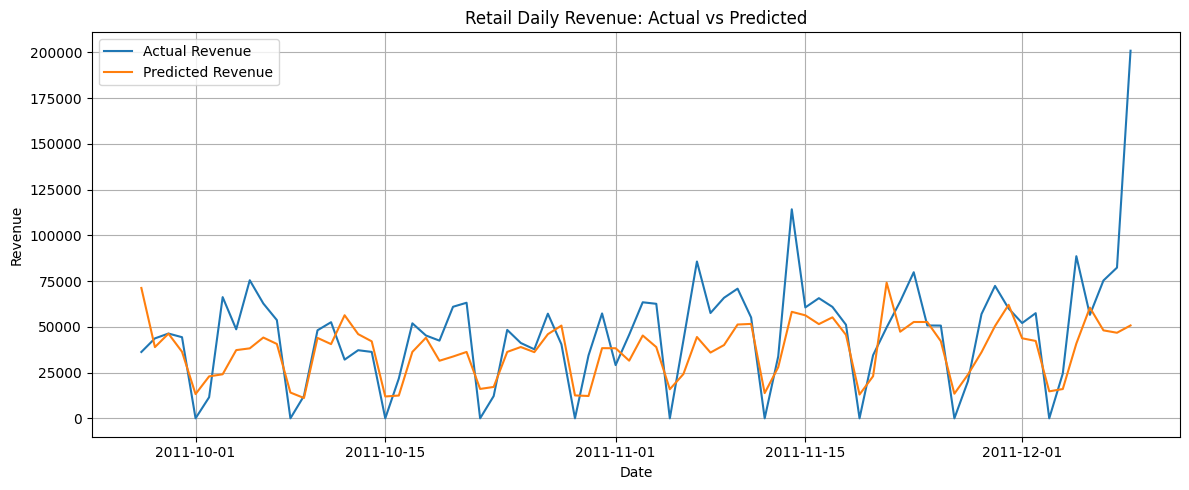

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    results.index,
    results["Actual_Revenue"],
    label="Actual Revenue"
)

plt.plot(
    results.index,
    results["Predicted_Revenue"],
    label="Predicted Revenue"
)

plt.title("Retail Daily Revenue: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [42]:
coefficient_table = pd.DataFrame({
    "Feature": features,
    "Coefficient": retail_model.coef_
})

print("Intercept:", round(retail_model.intercept_, 2))
print(coefficient_table.round(3))

Intercept: 7586.9
                  Feature  Coefficient
0           Revenue_Lag_1        0.176
1           Revenue_Lag_7        0.561
2  Previous_7_Day_Average       -0.065


In [43]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline: predict that revenue equals the previous day's revenue
baseline_predictions = X_test["Revenue_Lag_1"].to_numpy()

# Regression model predictions
model_predictions = retail_model.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Previous-day baseline", "Linear Regression"],
    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, model_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, model_predictions))
    ],
    "R2": [
        r2_score(y_test, baseline_predictions),
        r2_score(y_test, model_predictions)
    ]
})

print(comparison.round(3))

                   Model        MAE       RMSE     R2
0  Previous-day baseline  24946.256  33145.562 -0.165
1      Linear Regression  17207.497  25837.461  0.292


In [44]:
# Start from the daily sales data created earlier
improved_data = daily_sales.copy()

# Calendar features
improved_data["DayOfWeek"] = improved_data.index.dayofweek
improved_data["Month"] = improved_data.index.month

# Past revenue features
improved_data["Revenue_Lag_1"] = (
    improved_data["Revenue"].shift(1)
)

improved_data["Revenue_Lag_7"] = (
    improved_data["Revenue"].shift(7)
)

improved_data["Previous_7_Day_Average"] = (
    improved_data["Revenue"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

improved_data = improved_data.dropna()

print(improved_data.head())

              Revenue  Revenue_Lag_1  Revenue_Lag_7  Previous_7_Day_Average  \
InvoiceDate                                                                   
2010-12-08   45235.36       99553.85       58776.79            48406.781429   
2010-12-09   53548.19       45235.36       47629.42            46472.291429   
2010-12-10   59021.02       53548.19       46898.63            47317.830000   
2010-12-11       0.00       59021.02           0.00            49049.600000   
2010-12-12   17125.65           0.00       31364.63            49049.600000   

             DayOfWeek  Month  
InvoiceDate                    
2010-12-08           2     12  
2010-12-09           3     12  
2010-12-10           4     12  
2010-12-11           5     12  
2010-12-12           6     12  


In [45]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

features_improved = [
    "Revenue_Lag_1",
    "Revenue_Lag_7",
    "Previous_7_Day_Average",
    "DayOfWeek",
    "Month"
]

X = improved_data[features_improved]
y = improved_data["Revenue"]

split_index = int(len(improved_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

improved_model = LinearRegression()
improved_model.fit(X_train, y_train)

improved_predictions = improved_model.predict(X_test)

print("Improved model trained successfully!")

Improved model trained successfully!


In [46]:
baseline_predictions = X_test["Revenue_Lag_1"].to_numpy()

comparison = pd.DataFrame({
    "Model": [
        "Previous-day baseline",
        "Original Linear Regression",
        "Improved Linear Regression"
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(
            y_test,
            retail_model.predict(
                X_test[
                    [
                        "Revenue_Lag_1",
                        "Revenue_Lag_7",
                        "Previous_7_Day_Average"
                    ]
                ]
            )
        ),
        mean_absolute_error(y_test, improved_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(
            y_test,
            retail_model.predict(
                X_test[
                    [
                        "Revenue_Lag_1",
                        "Revenue_Lag_7",
                        "Previous_7_Day_Average"
                    ]
                ]
            )
        )),
        np.sqrt(mean_squared_error(y_test, improved_predictions))
    ],
    "R2": [
        r2_score(y_test, baseline_predictions),
        r2_score(
            y_test,
            retail_model.predict(
                X_test[
                    [
                        "Revenue_Lag_1",
                        "Revenue_Lag_7",
                        "Previous_7_Day_Average"
                    ]
                ]
            )
        ),
        r2_score(y_test, improved_predictions)
    ]
})

print(comparison.round(3))

                        Model        MAE       RMSE     R2
0       Previous-day baseline  24946.256  33145.562 -0.165
1  Original Linear Regression  17207.497  25837.461  0.292
2  Improved Linear Regression  17060.665  25978.769  0.284


In [47]:
# Use the original model and its matching test features
original_features = [
    "Revenue_Lag_1",
    "Revenue_Lag_7",
    "Previous_7_Day_Average"
]

original_predictions = retail_model.predict(
    X_test[original_features]
)

forecast_results = pd.DataFrame({
    "Date": y_test.index,
    "Actual_Revenue": y_test.values,
    "Predicted_Revenue": original_predictions
})

forecast_results["Absolute_Error"] = (
    forecast_results["Actual_Revenue"]
    - forecast_results["Predicted_Revenue"]
).abs()

forecast_results["Error"] = (
    forecast_results["Actual_Revenue"]
    - forecast_results["Predicted_Revenue"]
)

print(forecast_results.head(10).round(2))

        Date  Actual_Revenue  Predicted_Revenue  Absolute_Error     Error
0 2011-09-27        36260.91           71248.14        34987.23 -34987.23
1 2011-09-28        43693.08           38925.26         4767.82   4767.82
2 2011-09-29        46343.35           46273.70           69.65     69.65
3 2011-09-30        44347.06           36400.08         7946.98   7946.98
4 2011-10-01            0.00           13255.78        13255.78 -13255.78
5 2011-10-02        11531.56           22935.32        11403.76 -11403.76
6 2011-10-03        66243.94           24082.61        42161.33  42161.33
7 2011-10-04        48652.54           37286.47        11366.07  11366.07
8 2011-10-05        75460.77           38246.44        37214.33  37214.33
9 2011-10-06        62761.92           44155.61        18606.31  18606.31


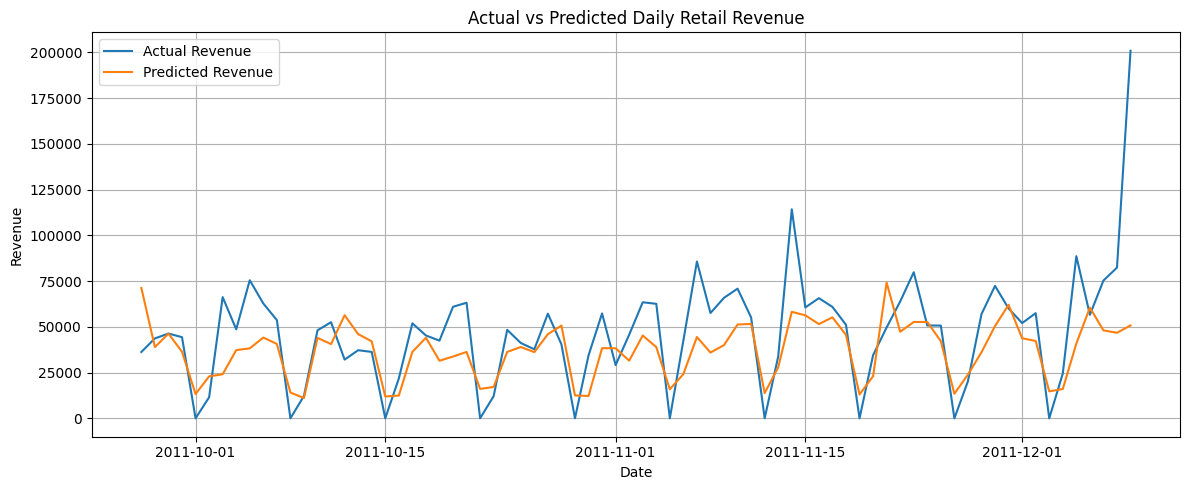

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    forecast_results["Date"],
    forecast_results["Actual_Revenue"],
    label="Actual Revenue"
)

plt.plot(
    forecast_results["Date"],
    forecast_results["Predicted_Revenue"],
    label="Predicted Revenue"
)

plt.title("Actual vs Predicted Daily Retail Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [49]:
forecast_results.to_csv(
    "retail_revenue_predictions.csv",
    index=False
)

print("Forecast results exported successfully!")

Forecast results exported successfully!


In [50]:
# Show the 10 dates with the largest prediction errors
largest_errors = (
    forecast_results
    .sort_values("Absolute_Error", ascending=False)
    [["Date", "Actual_Revenue", "Predicted_Revenue", "Absolute_Error"]]
    .head(10)
)

print(largest_errors.round(2).to_string(index=False))

      Date  Actual_Revenue  Predicted_Revenue  Absolute_Error
2011-12-09       200900.98           50764.83       150136.15
2011-11-14       114237.40           58214.21        56023.19
2011-12-05        88620.84           40861.14        47759.70
2011-10-03        66243.94           24082.61        42161.33
2011-11-07        85705.30           44446.64        41258.66
2011-10-05        75460.77           38246.44        37214.33
2011-12-08        82371.55           46769.94        35601.61
2011-09-27        36260.91           71248.14        34987.23
2011-12-07        75315.55           48074.67        27240.88
2011-10-20        60969.14           33773.17        27195.97


In [51]:
# Find the date with the highest actual revenue in the test period
peak_date = forecast_results.loc[
    forecast_results["Actual_Revenue"].idxmax(),
    "Date"
]

print("Peak sales date:", peak_date)

# Inspect the original transactions on that date
peak_transactions = sales[
    sales["InvoiceDate"].dt.date == peak_date.date()
]

print("Transaction rows:", len(peak_transactions))
print("Unique invoices:", peak_transactions["InvoiceNo"].nunique())
print("Total revenue:", round(peak_transactions["Revenue"].sum(), 2))

print(
    peak_transactions
    .groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Peak sales date: 2011-12-09 00:00:00
Transaction rows: 1618
Unique invoices: 44
Total revenue: 200900.98
Description
PAPER CRAFT , LITTLE BIRDIE          168469.60
DOTCOM POSTAGE                         2647.34
BLACK RECORD COVER FRAME                669.57
PAPER CHAIN KIT 50'S CHRISTMAS          591.90
RABBIT NIGHT LIGHT                      571.41
HOT WATER BOTTLE TEA AND SYMPATHY       538.56
ASSORTED COLOUR MINI CASES              533.40
HOME SWEET HOME BLACKBOARD              469.44
HOT WATER BOTTLE KEEP CALM              437.04
REGENCY CAKESTAND 3 TIER                327.18
Name: Revenue, dtype: float64


In [52]:
import pandas as pd

peak_date = pd.Timestamp("2011-12-09")

peak_product = sales[
    (sales["InvoiceDate"].dt.date == peak_date.date())
    & (sales["Description"] == "PAPER CRAFT , LITTLE BIRDIE")
].copy()

print("Transaction rows:", len(peak_product))
print("Unique invoices:", peak_product["InvoiceNo"].nunique())
print("Total units:", peak_product["Quantity"].sum())
print("Total revenue:", round(peak_product["Revenue"].sum(), 2))

print(
    peak_product[
        ["InvoiceNo", "Quantity", "UnitPrice", "Revenue"]
    ].sort_values("Revenue", ascending=False).head(15).to_string(index=False)
)

Transaction rows: 1
Unique invoices: 1
Total units: 80995
Total revenue: 168469.6
InvoiceNo  Quantity  UnitPrice  Revenue
   581483     80995       2.08 168469.6


In [53]:
product_daily = (
    sales[sales["Description"] == "PAPER CRAFT , LITTLE BIRDIE"]
    .groupby(sales["InvoiceDate"].dt.floor("D"))["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top revenue days for this product:")
print(product_daily.head(10).round(2))

Top revenue days for this product:
InvoiceDate
2011-12-09    168469.6
Name: Revenue, dtype: float64


In [54]:
invoice_check = df_original[
    df_original["InvoiceNo"].astype(str) == "581483"
]

print(invoice_check.to_string(index=False))

InvoiceNo StockCode                 Description  Quantity         InvoiceDate  UnitPrice  CustomerID        Country
   581483     23843 PAPER CRAFT , LITTLE BIRDIE     80995 2011-12-09 09:15:00       2.08     16446.0 United Kingdom


In [55]:
peak_invoice = "581483"

sales_without_peak = sales[
    sales["InvoiceNo"].astype(str) != peak_invoice
].copy()

daily_without_peak = (
    sales_without_peak
    .set_index("InvoiceDate")["Revenue"]
    .resample("D")
    .sum()
)

print("Original 9 Dec revenue:",
      round(daily_sales.loc["2011-12-09", "Revenue"], 2))

print("Revenue without invoice 581483:",
      round(daily_without_peak.loc["2011-12-09"], 2))

Original 9 Dec revenue: 200900.98
Revenue without invoice 581483: 32431.38


In [56]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Experiment A: all recorded sales
sales_all = sales.copy()

# Experiment B: exclude only the unusual invoice
sales_filtered = sales[
    sales["InvoiceNo"].astype(str) != "581483"
].copy()


def prepare_daily_data(transaction_data):
    daily = (
        transaction_data
        .set_index("InvoiceDate")["Revenue"]
        .resample("D")
        .sum()
        .rename("Revenue")
        .to_frame()
    )

    daily["Revenue_Lag_1"] = daily["Revenue"].shift(1)
    daily["Revenue_Lag_7"] = daily["Revenue"].shift(7)

    daily["Previous_7_Day_Average"] = (
        daily["Revenue"]
        .shift(1)
        .rolling(7)
        .mean()
    )

    return daily.dropna()


daily_all = prepare_daily_data(sales_all)
daily_filtered = prepare_daily_data(sales_filtered)

# Use identical dates for both experiments
common_dates = daily_all.index.intersection(daily_filtered.index)

daily_all = daily_all.loc[common_dates]
daily_filtered = daily_filtered.loc[common_dates]

features = [
    "Revenue_Lag_1",
    "Revenue_Lag_7",
    "Previous_7_Day_Average"
]

# Chronological split
split_index = int(len(common_dates) * 0.8)
test_dates = common_dates[split_index:]


def evaluate_model(daily, target_dates):
    train_dates = daily.index[daily.index < target_dates[0]]

    X_train = daily.loc[train_dates, features]
    y_train = daily.loc[train_dates, "Revenue"]

    X_test = daily.loc[target_dates, features]
    y_test = daily.loc[target_dates, "Revenue"]

    model = LinearRegression()
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    return {
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    }


results_comparison = pd.DataFrame([
    {
        "Experiment": "All recorded sales",
        **evaluate_model(daily_all, test_dates)
    },
    {
        "Experiment": "Without invoice 581483",
        **evaluate_model(daily_filtered, test_dates)
    }
])

print(results_comparison.round(3).to_string(index=False))

            Experiment       MAE      RMSE    R2
    All recorded sales 17207.497 25837.461 0.292
Without invoice 581483 15426.380 19170.556 0.407


In [57]:
# Export the original model's forecast results
forecast_results.to_csv(
    "retail_revenue_predictions.csv",
    index=False
)

# Export the model comparison
results_comparison.to_csv(
    "retail_forecasting_model_comparison.csv",
    index=False
)

print("Forecast results exported successfully.")
print("Model comparison exported successfully.")

Forecast results exported successfully.
Model comparison exported successfully.


In [58]:
print("Last transaction date:", sales["InvoiceDate"].max())
print("Last recorded revenue date:", daily_sales.index.max())

Last transaction date: 2011-12-09 12:50:00
Last recorded revenue date: 2011-12-09 00:00:00


In [59]:
daily_revenue = (
    sales
    .set_index("InvoiceDate")["Revenue"]
    .resample("D")
    .sum()
    .rename("Revenue")
    .to_frame()
)

print(daily_revenue.tail(10))

               Revenue
InvoiceDate           
2011-11-30    60025.57
2011-12-01    52068.63
2011-12-02    57476.48
2011-12-03        0.00
2011-12-04    24477.47
2011-12-05    88620.84
2011-12-06    56558.83
2011-12-07    75315.55
2011-12-08    82371.55
2011-12-09   200900.98


In [60]:
forecast_data = daily_revenue.copy()

forecast_data["Revenue_Lag_1"] = (
    forecast_data["Revenue"].shift(1)
)

forecast_data["Revenue_Lag_7"] = (
    forecast_data["Revenue"].shift(7)
)

forecast_data["Previous_7_Day_Average"] = (
    forecast_data["Revenue"]
    .shift(1)
    .rolling(7)
    .mean()
)

forecast_data = forecast_data.dropna()

print(forecast_data.tail())

               Revenue  Revenue_Lag_1  Revenue_Lag_7  Previous_7_Day_Average
InvoiceDate                                                                 
2011-12-05    88620.84       24477.47       56965.73            46199.814286
2011-12-06    56558.83       88620.84       72384.82            50721.972857
2011-12-07    75315.55       56558.83       60025.57            48461.117143
2011-12-08    82371.55       75315.55       52068.63            50645.400000
2011-12-09   200900.98       82371.55       57476.48            54974.388571


In [61]:
from sklearn.linear_model import LinearRegression

features = [
    "Revenue_Lag_1",
    "Revenue_Lag_7",
    "Previous_7_Day_Average"
]

last_observed_date = daily_revenue.index.max()

training_data = forecast_data[
    forecast_data.index < last_observed_date
]

X_train = training_data[features]
y_train = training_data["Revenue"]

next_day_model = LinearRegression()
next_day_model.fit(X_train, y_train)

print("Training completed!")
print("Training ends:", training_data.index.max())

Training completed!
Training ends: 2011-12-08 00:00:00


In [62]:
last_date = daily_revenue.index.max()
next_date = last_date + pd.Timedelta(days=1)

next_day_features = pd.DataFrame({
    "Revenue_Lag_1": [
        daily_revenue.loc[last_date, "Revenue"]
    ],
    "Revenue_Lag_7": [
        daily_revenue.loc[next_date - pd.Timedelta(days=7), "Revenue"]
    ],
    "Previous_7_Day_Average": [
        daily_revenue.loc[
            next_date - pd.Timedelta(days=7):
            next_date - pd.Timedelta(days=1),
            "Revenue"
        ].mean()
    ]
})

predicted_revenue = next_day_model.predict(next_day_features)[0]

print("Last observed date:", last_date.date())
print("Forecast date:", next_date.date())
print("Predicted revenue:", round(predicted_revenue, 2))

Last observed date: 2011-12-09
Forecast date: 2011-12-10
Predicted revenue: 43209.93


In [63]:
next_day_forecast = pd.DataFrame({
    "Forecast_Date": [next_date],
    "Predicted_Revenue": [predicted_revenue]
})

next_day_forecast.to_csv(
    "retail_next_day_forecast.csv",
    index=False
)

print(next_day_forecast.round(2))
print("Forecast saved successfully!")

  Forecast_Date  Predicted_Revenue
0    2011-12-10           43209.93
Forecast saved successfully!


In [64]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Model Evaluation")
print("----------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 3))

Model Evaluation
----------------
MAE: 17207.5
RMSE: 25837.46
R² Score: 0.292


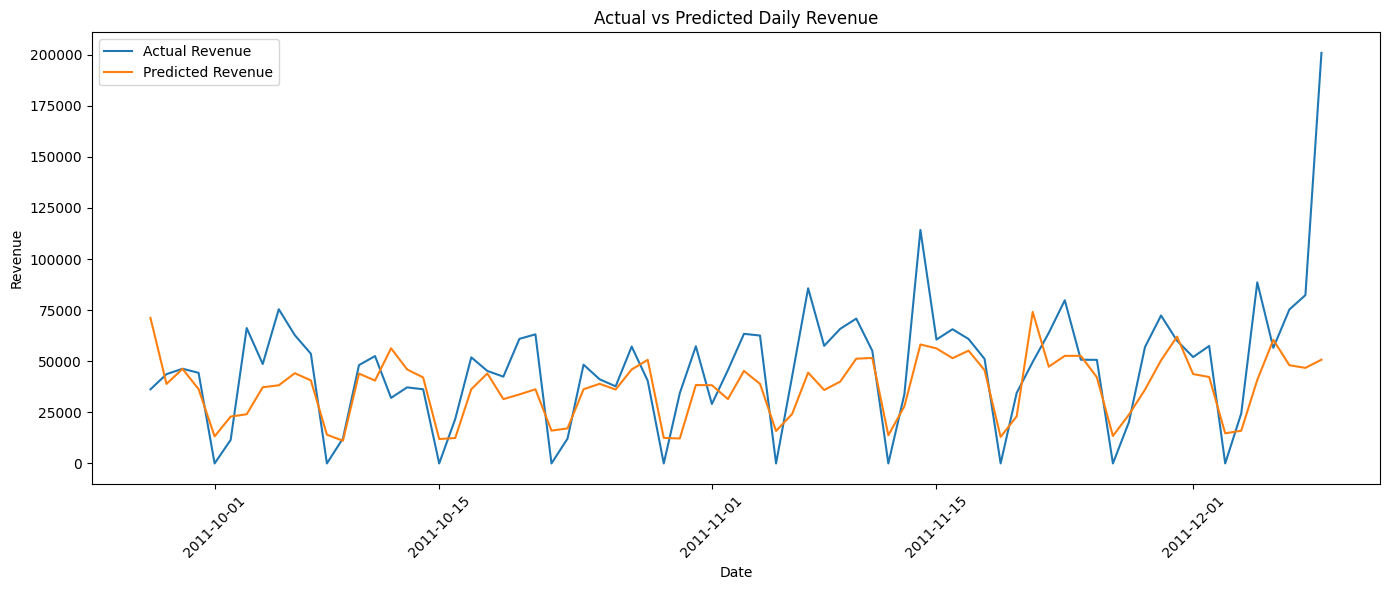

In [65]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Revenue"
)

plt.plot(
    y_test.index,
    predictions,
    label="Predicted Revenue"
)

plt.title("Actual vs Predicted Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [66]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Use the same features as the Linear Regression model
features = [
    "Revenue_Lag_1",
    "Revenue_Lag_7",
    "Previous_7_Day_Average"
]

# Create the same chronological training/test split
split_index = int(len(model_data) * 0.8)

X = model_data[features]
y = model_data["Revenue"]

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predict test-period revenue
rf_predictions = rf_model.predict(X_test)

# Evaluate
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Evaluation")
print("------------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R² Score:", round(rf_r2, 3))


Random Forest Evaluation
------------------------
MAE: 14062.86
RMSE: 23973.57
R² Score: 0.391


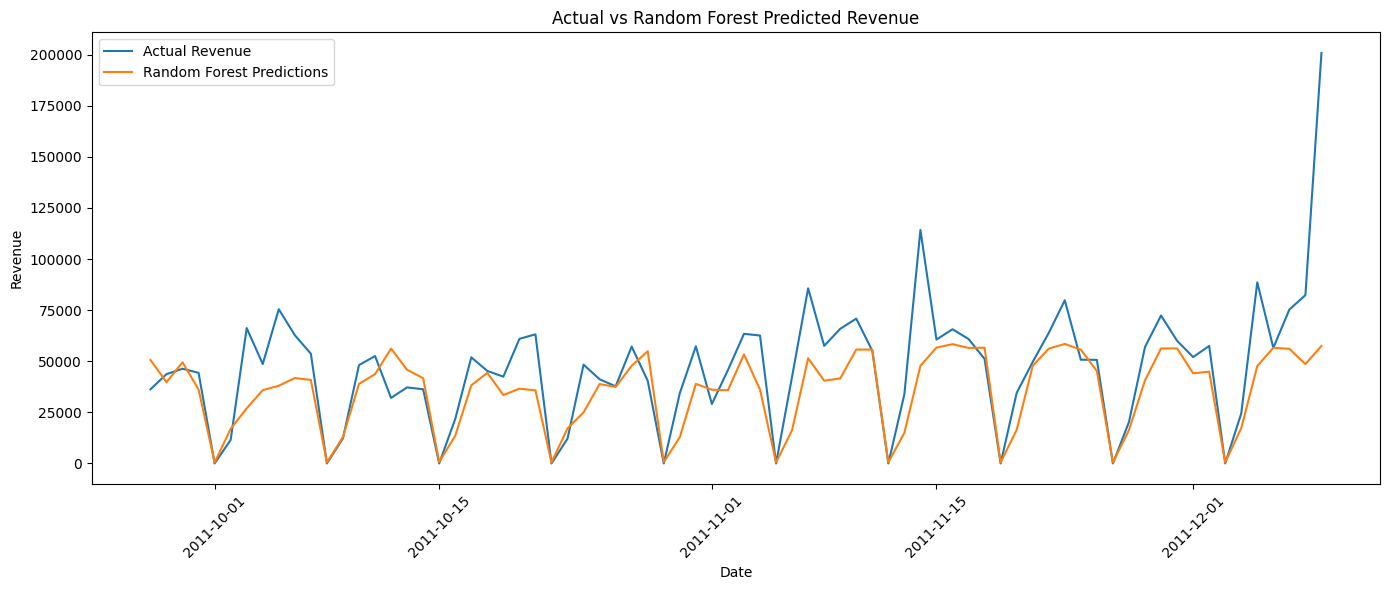

In [67]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Revenue"
)

plt.plot(
    y_test.index,
    rf_predictions,
    label="Random Forest Predictions"
)

plt.title("Actual vs Random Forest Predicted Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [68]:

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate Linear Regression
linear_mae = mean_absolute_error(y_test, predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, predictions))
linear_r2 = r2_score(y_test, predictions)

# Evaluate Random Forest
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

# Create comparison table
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, rf_mae],
    "RMSE": [linear_rmse, rf_rmse],
    "R2_Score": [linear_r2, rf_r2]
})

print(model_comparison.round(3))

# Save results
model_comparison.to_csv(
    "retail_ml_model_comparison.csv",
    index=False
)

print("\nModel comparison saved successfully!")


               Model        MAE       RMSE  R2_Score
0  Linear Regression  17207.497  25837.461     0.292
1      Random Forest  14062.860  23973.567     0.391

Model comparison saved successfully!


In [69]:

# Create a separate copy; keep the original model_data unchanged
calendar_data = model_data.copy()

calendar_data["DayOfWeek"] = calendar_data.index.dayofweek
calendar_data["Month"] = calendar_data.index.month

calendar_features = [
    "Revenue_Lag_1",
    "Revenue_Lag_7",
    "Previous_7_Day_Average",
    "DayOfWeek",
    "Month"
]

print(calendar_data[calendar_features + ["Revenue"]].head())


             Revenue_Lag_1  Revenue_Lag_7  Previous_7_Day_Average  DayOfWeek  \
InvoiceDate                                                                    
2010-12-08        99553.85       58776.79            48406.781429          2   
2010-12-09        45235.36       47629.42            46472.291429          3   
2010-12-10        53548.19       46898.63            47317.830000          4   
2010-12-11        59021.02           0.00            49049.600000          5   
2010-12-12            0.00       31364.63            49049.600000          6   

             Month   Revenue  
InvoiceDate                   
2010-12-08      12  45235.36  
2010-12-09      12  53548.19  
2010-12-10      12  59021.02  
2010-12-11      12      0.00  
2010-12-12      12  17125.65  


In [70]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

X = calendar_data[calendar_features]
y = calendar_data["Revenue"]

split_index = int(len(calendar_data) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

models = {
    "Linear Regression + Calendar": LinearRegression(),
    "Random Forest + Calendar": RandomForestRegressor(
        n_estimators=200,
        max_depth=6,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
}

comparison = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    comparison.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2_Score": r2_score(y_test, pred)
    })

calendar_comparison = pd.DataFrame(comparison)
print(calendar_comparison.round(3))

calendar_comparison.to_csv(
    "retail_calendar_model_comparison.csv",
    index=False
)

print("\nCalendar model comparison saved successfully!")


                          Model        MAE       RMSE  R2_Score
0  Linear Regression + Calendar  17060.665  25978.769     0.284
1      Random Forest + Calendar  13788.144  23796.083     0.400

Calendar model comparison saved successfully!


                  Feature  Importance
1           Revenue_Lag_7      0.3733
3               DayOfWeek      0.3478
2  Previous_7_Day_Average      0.1183
0           Revenue_Lag_1      0.0934
4                   Month      0.0673


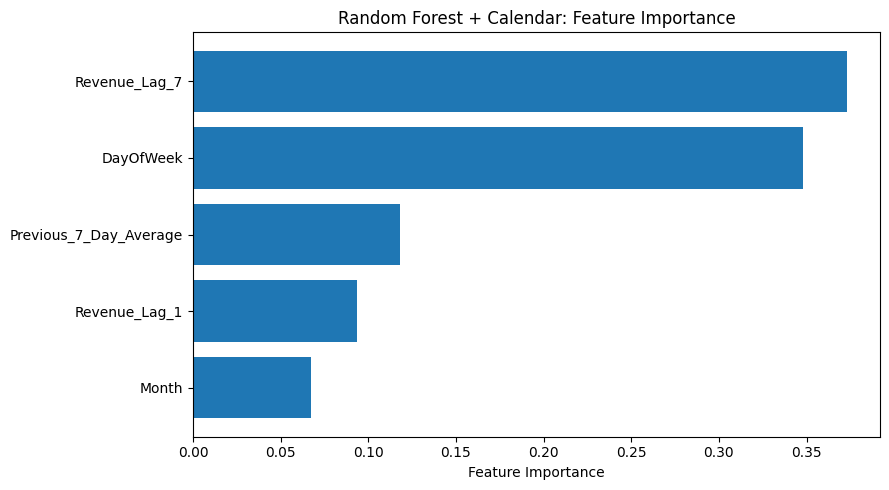

In [71]:

# The models dictionary contains the trained models from Lesson 10
best_model = models["Random Forest + Calendar"]

importance = pd.DataFrame({
    "Feature": calendar_features,
    "Importance": best_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance.round(4))

# Visualize feature importance
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Feature Importance")
plt.title("Random Forest + Calendar: Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [72]:

import joblib

best_model = models["Random Forest + Calendar"]

joblib.dump(
    best_model,
    "models/retail_best_model.pkl"
)

joblib.dump(
    calendar_features,
    "models/retail_model_features.pkl"
)

print("Best model saved successfully!")
print("Model: Random Forest + Calendar")


Best model saved successfully!
Model: Random Forest + Calendar


In [73]:

# Summarize revenue by day of the week

weekday_summary = daily_revenue.copy()

weekday_summary["DayOfWeek"] = (
    weekday_summary.index.day_name()
)

weekday_summary = weekday_summary.groupby(
    "DayOfWeek"
)["Revenue"].agg(
    Days="count",
    Average_Revenue="mean",
    Median_Revenue="median",
    Zero_Revenue_Days=lambda x: (x == 0).sum()
)

weekday_summary = weekday_summary.reindex([
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
])

print(weekday_summary.round(2))


           Days  Average_Revenue  Median_Revenue  Zero_Revenue_Days
DayOfWeek                                                          
Monday       53         33505.32        29262.72                  6
Tuesday      53         41050.95        35545.83                  1
Wednesday    54         34205.08        28367.76                  1
Thursday     54         40727.64        36431.96                  1
Friday       54         34027.23        28209.74                  4
Saturday     53             0.00            0.00                 53
Sunday       53         15222.47        12156.57                  3


In [74]:

def predict_next_day_revenue(daily_revenue, model, features):
    daily_revenue = daily_revenue.sort_index()

    last_date = daily_revenue.index.max()
    forecast_date = last_date + pd.Timedelta(days=1)

    lag_1 = daily_revenue.loc[last_date, "Revenue"]

    lag_7_date = forecast_date - pd.Timedelta(days=7)
    lag_7 = daily_revenue.loc[lag_7_date, "Revenue"]

    average_start = forecast_date - pd.Timedelta(days=7)
    average_end = forecast_date - pd.Timedelta(days=1)

    previous_average = daily_revenue.loc[
        average_start:average_end, "Revenue"
    ].mean()

    input_data = pd.DataFrame([{
        "Revenue_Lag_1": lag_1,
        "Revenue_Lag_7": lag_7,
        "Previous_7_Day_Average": previous_average,
        "DayOfWeek": forecast_date.dayofweek,
        "Month": forecast_date.month
    }])

    input_data = input_data[features]

    print("Forecast input values:")
    print(input_data)

    prediction = model.predict(input_data)[0]

    print("\nRaw prediction:", prediction)

    return forecast_date, prediction


In [75]:

import joblib
import numpy as np

# Load the saved model
loaded_model = joblib.load("models/retail_best_model.pkl")

print("Model type:", type(loaded_model))
print("Number of expected features:", loaded_model.n_features_in_)
print("Feature importances:", loaded_model.feature_importances_)

# Check the model's predictions on known test data
print("\nFirst 5 actual test values:")
print(y_test.head())

print("\nPredictions from the saved model:")
print(loaded_model.predict(X_test.iloc[:5]))

# Compare with the model currently in memory
print("\nPredictions from the in-memory model:")
print(models["Random Forest + Calendar"].predict(X_test.iloc[:5]))


Model type: <class 'sklearn.ensemble._forest.RandomForestRegressor'>
Number of expected features: 5
Feature importances: [0.0933527  0.37325493 0.11830219 0.34781738 0.0672728 ]

First 5 actual test values:
InvoiceDate
2011-09-27    36260.91
2011-09-28    43693.08
2011-09-29    46343.35
2011-09-30    44347.06
2011-10-01        0.00
Freq: D, Name: Revenue, dtype: float64

Predictions from the saved model:
[5.48729673e+04 4.07111883e+04 5.33957254e+04 3.65999829e+04
 2.88365900e+01]

Predictions from the in-memory model:
[5.48729673e+04 4.07111883e+04 5.33957254e+04 3.65999829e+04
 2.88365900e+01]


In [76]:

# Inspect the row where the model predicted 28.84
print("Fifth test row — input features:")
print(X_test.iloc[[4]])

print("\nActual revenue:")
print(y_test.iloc[4])

print("\nPrediction:")
print(loaded_model.predict(X_test.iloc[[4]])[0])

# Check the original daily revenue around this date
test_date = X_test.index[4]

print("\nDaily revenue around this date:")
print(daily_revenue.loc[
    test_date - pd.Timedelta(days=3):
    test_date + pd.Timedelta(days=3)
])


Fifth test row — input features:
             Revenue_Lag_1  Revenue_Lag_7  Previous_7_Day_Average  DayOfWeek  \
InvoiceDate                                                                    
2011-10-01        44347.06            0.0            33011.431714          5   

             Month  
InvoiceDate         
2011-10-01      10  

Actual revenue:
0.0

Prediction:
28.83659

Daily revenue around this date:
              Revenue
InvoiceDate          
2011-09-28   43693.08
2011-09-29   46343.35
2011-09-30   44347.06
2011-10-01       0.00
2011-10-02   11531.56
2011-10-03   66243.94
2011-10-04   48652.54


In [77]:

# Find zero-revenue days in the training data
zero_days = y_train[y_train == 0]

print("Zero-revenue days in training:", len(zero_days))
print("\nTheir dates:")
print(zero_days.index.tolist())

# Check the feature values for zero-revenue training days
print("\nFeatures for zero-revenue training days:")
print(X_train.loc[zero_days.index])



Zero-revenue days in training: 58

Their dates:
[Timestamp('2010-12-11 00:00:00'), Timestamp('2010-12-18 00:00:00'), Timestamp('2010-12-24 00:00:00'), Timestamp('2010-12-25 00:00:00'), Timestamp('2010-12-26 00:00:00'), Timestamp('2010-12-27 00:00:00'), Timestamp('2010-12-28 00:00:00'), Timestamp('2010-12-29 00:00:00'), Timestamp('2010-12-30 00:00:00'), Timestamp('2010-12-31 00:00:00'), Timestamp('2011-01-01 00:00:00'), Timestamp('2011-01-02 00:00:00'), Timestamp('2011-01-03 00:00:00'), Timestamp('2011-01-08 00:00:00'), Timestamp('2011-01-15 00:00:00'), Timestamp('2011-01-22 00:00:00'), Timestamp('2011-01-29 00:00:00'), Timestamp('2011-02-05 00:00:00'), Timestamp('2011-02-12 00:00:00'), Timestamp('2011-02-19 00:00:00'), Timestamp('2011-02-26 00:00:00'), Timestamp('2011-03-05 00:00:00'), Timestamp('2011-03-12 00:00:00'), Timestamp('2011-03-19 00:00:00'), Timestamp('2011-03-26 00:00:00'), Timestamp('2011-04-02 00:00:00'), Timestamp('2011-04-09 00:00:00'), Timestamp('2011-04-16 00:00:00'),

In [78]:
# Generate predictions using the trained Random Forest + Calendar model

current_model = models["Random Forest + Calendar"]

current_predictions = current_model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(current_predictions))

Predictions generated successfully!
Number of predictions: 74


In [79]:

# Create the final forecasting results

final_forecast = pd.DataFrame({
    "Date": y_test.index,
    "Actual_Revenue": y_test.values,
    "Predicted_Revenue": current_predictions
})

final_forecast["Prediction_Error"] = (
    final_forecast["Actual_Revenue"]
    - final_forecast["Predicted_Revenue"]
)

final_forecast["Absolute_Error"] = (
    final_forecast["Prediction_Error"].abs()
)

final_forecast["DayOfWeek"] = (
    pd.to_datetime(final_forecast["Date"]).dt.day_name()
)

final_forecast.to_csv(
    "outputs/retail_final_forecast.csv",
    index=False
)

print("Final forecast exported successfully!")
print(final_forecast.head(10))


Final forecast exported successfully!
        Date  Actual_Revenue  Predicted_Revenue  Prediction_Error  \
0 2011-09-27        36260.91       54872.967286     -18612.057286   
1 2011-09-28        43693.08       40711.188275       2981.891725   
2 2011-09-29        46343.35       53395.725448      -7052.375448   
3 2011-09-30        44347.06       36599.982944       7747.077056   
4 2011-10-01            0.00          28.836590        -28.836590   
5 2011-10-02        11531.56       17228.296980      -5696.736980   
6 2011-10-03        66243.94       29361.470275      36882.469725   
7 2011-10-04        48652.54       36566.382353      12086.157647   
8 2011-10-05        75460.77       38480.669691      36980.100309   
9 2011-10-06        62761.92       42035.455847      20726.464153   

   Absolute_Error  DayOfWeek  
0    18612.057286    Tuesday  
1     2981.891725  Wednesday  
2     7052.375448   Thursday  
3     7747.077056     Friday  
4       28.836590   Saturday  
5     5696.73698

In [80]:

import os

for file in [
    "retail_final_forecast.csv",
    "retail_final_model_comparison.csv",
    "retail_best_model.pkl",
    "retail_model_features.pkl"
]:
    print(f"{file}: {'Found' if os.path.exists(file) else 'Missing'}")


retail_final_forecast.csv: Missing
retail_final_model_comparison.csv: Missing
retail_best_model.pkl: Missing
retail_model_features.pkl: Missing


In [81]:

import os

folders = [
    "data",
    "outputs",
    "models",
    "dashboard",
    "reports",
    "images"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

for folder in folders:
    print(folder)


Project folders created successfully!
data
outputs
models
dashboard
reports
images


In [82]:

import os
import shutil

base = os.getcwd()

file_moves = {
    "data": [
        "Online Retail.xlsx"
    ],
    "outputs": [
        "country_sales.csv",
        "monthly_sales.csv",
        "retail_calendar_model_comparison.csv",
        "retail_final_forecast.csv",
        "retail_final_model_comparison.csv",
        "retail_forecasting_model_comparison.csv",
        "retail_kpi_summary.csv",
        "retail_ml_model_comparison.csv",
        "retail_monthly_analysis.csv",
        "retail_next_day_forecast.csv",
        "retail_revenue_predictions.csv",
        "top_customers.csv",
        "top_products.csv"
    ],
    "models": [
        "retail_best_model.pkl",
        "retail_model_features.pkl"
    ],
    "dashboard": [
        "Retail_Sales_Analytics.pbix"
    ]
}

for folder, files in file_moves.items():
    for filename in files:
        source = os.path.join(base, filename)
        destination = os.path.join(base, folder, filename)

        if not os.path.exists(source):
            print("Not found:", filename)
        elif os.path.exists(destination):
            print("Skipped (already exists):", destination)
        else:
            shutil.move(source, destination)
            print("Moved:", filename, "->", folder)

print("\nFile organization finished.")
print("Your notebook remains in the main project folder.")


Not found: Online Retail.xlsx
Skipped (already exists): C:\Users\rajan\OneDrive\Desktop\Retail_Sales_Analytics\outputs\country_sales.csv
Skipped (already exists): C:\Users\rajan\OneDrive\Desktop\Retail_Sales_Analytics\outputs\monthly_sales.csv
Skipped (already exists): C:\Users\rajan\OneDrive\Desktop\Retail_Sales_Analytics\outputs\retail_calendar_model_comparison.csv
Not found: retail_final_forecast.csv
Not found: retail_final_model_comparison.csv
Skipped (already exists): C:\Users\rajan\OneDrive\Desktop\Retail_Sales_Analytics\outputs\retail_forecasting_model_comparison.csv
Skipped (already exists): C:\Users\rajan\OneDrive\Desktop\Retail_Sales_Analytics\outputs\retail_kpi_summary.csv
Skipped (already exists): C:\Users\rajan\OneDrive\Desktop\Retail_Sales_Analytics\outputs\retail_ml_model_comparison.csv
Skipped (already exists): C:\Users\rajan\OneDrive\Desktop\Retail_Sales_Analytics\outputs\retail_monthly_analysis.csv
Skipped (already exists): C:\Users\rajan\OneDrive\Desktop\Retail_Sales

In [83]:

import os
import shutil

base = os.getcwd()

source = os.path.join(
    base, "Retail_Sales_Analytics.pbix"
)

destination = os.path.join(
    base, "dashboard", "Retail_Sales_Analytics.pbix"
)

if os.path.exists(destination):
    print("Power BI file is already in the dashboard folder.")
elif os.path.exists(source):
    try:
        shutil.move(source, destination)
        print("Power BI file moved successfully!")
    except PermissionError:
        print("Still in use. Close Power BI Desktop and try again.")
else:
    print("File not found in the main folder. Check its location.")


Power BI file is already in the dashboard folder.


In [84]:

import os

for folder in ["data", "outputs", "models", "dashboard"]:
    path = os.path.join(os.getcwd(), folder)

    print(f"\n📁 {folder}/")

    if os.path.exists(path):
        for file in os.listdir(path):
            print("   ", file)
    else:
        print("    Folder not found")



📁 data/
    Online Retail.xlsx

📁 outputs/
    country_sales.csv
    monthly_sales.csv
    retail_calendar_model_comparison.csv
    retail_final_forecast.csv
    retail_final_model_comparison.csv
    retail_forecasting_model_comparison.csv
    retail_kpi_summary.csv
    retail_ml_model_comparison.csv
    retail_monthly_analysis.csv
    retail_next_day_forecast.csv
    retail_revenue_predictions.csv
    top_customers.csv
    top_products.csv

📁 models/
    retail_best_model.pkl
    retail_model_features.pkl

📁 dashboard/
    Retail_Sales_Analytics.pbix


In [85]:

from pathlib import Path

readme_content = r"""# Retail Sales Analytics & Revenue Forecasting

## Project Overview
This project analyzes online retail transactions to understand sales performance, identify business trends, and forecast daily revenue using machine learning.

## Business Objectives
- Analyze overall retail revenue and sales performance.
- Identify monthly revenue trends.
- Find top-performing products and countries.
- Analyze customer purchasing patterns.
- Build and evaluate daily revenue forecasting models.
- Present insights through a Power BI dashboard.

## Tools & Technologies
- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Jupyter Notebook
- Power BI
- Git and GitHub

## Project Structure
```text
Retail_Sales_Analytics/
├── Retail_Sales_Analytics.ipynb
├── README.md
├── data/
│   └── Online Retail.xlsx
├── outputs/
│   ├── retail_final_forecast.csv
│   ├── retail_final_model_comparison.csv
│   ├── retail_kpi_summary.csv
│   ├── monthly_sales.csv
│   ├── country_sales.csv
│   ├── top_products.csv
│   └── top_customers.csv
├── models/
│   ├── retail_best_model.pkl
│   └── retail_model_features.pkl
└── dashboard/
    └── Retail_Sales_Analytics.pbix
```

## Data Preparation
The workflow includes:
- Removing duplicate transactions.
- Excluding cancellation invoices from the sales analysis.
- Filtering non-positive quantities and unit prices.
- Converting invoice dates to datetime format.
- Calculating revenue as quantity multiplied by unit price.

Missing customer IDs limit customer-level analysis. Revenue calculations represent the cleaned sales data, not necessarily audited accounting revenue.

## Exploratory Data Analysis
The project explores:
- Overall revenue and transaction KPIs.
- Monthly revenue trends.
- Revenue by country.
- Best-performing products.
- Customer-level sales.
- Unusual transactions and zero-revenue days.

## Revenue Forecasting
The primary model is Random Forest with calendar and lag-based features.

Features include:
- Previous-day revenue.
- Revenue from seven days earlier.
- Previous seven-day average revenue.
- Day of week.
- Month.

### Model Evaluation

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Linear Regression + Calendar | 17060.665 | 25978.769 | 0.284 |
| Random Forest + Calendar | 13788.144 | 23796.083 | 0.400 |
| Random Forest + Calendar + Saturday Rule | 13784.248 | 23796.080 | 0.400 |

The Saturday adjustment produces only a negligible improvement in test metrics. It should only be used as a business rule if the zero-Saturday-sales pattern is confirmed as an operating constraint.

### Interpretation
- MAE measures average absolute prediction error.
- RMSE penalizes larger prediction errors more heavily.
- R² measures how much variation in the test-set revenue is explained by the model.

The results indicate that Random Forest performs better than the tested linear regression approach, but it still struggles to predict sudden revenue spikes.

## Power BI Dashboard
The Power BI report is saved in `dashboard/Retail_Sales_Analytics.pbix`.

Open it using Power BI Desktop to explore the dashboard and its available filters.

## Important Limitations
- The dataset covers December 2010 through December 9, 2011; December 2011 is incomplete.
- The dataset is historical and should not be treated as a current business forecast.
- Some unusually large transactions may substantially influence revenue and model evaluation.
- Missing customer IDs restrict customer-level analysis.
- Saturday revenue is zero throughout the cleaned dataset; the reason should be verified before applying a permanent business rule.
- Model metrics are based on a chronological holdout test set and may not generalize to other periods.

## How to Run
1. Install Python and Jupyter Notebook.
2. Install the required libraries:
   `pip install pandas numpy matplotlib scikit-learn openpyxl joblib`
3. Place the source dataset in the `data/` folder.
4. Open `Retail_Sales_Analytics.ipynb`.
5. Update file paths to match the project folder structure.
6. Run notebook cells in order.
7. Open the `.pbix` file in Power BI Desktop to view the dashboard.

## Future Improvements
- Compare forecasts with stronger seasonal baselines.
- Validate unusual transactions and operating-day assumptions.
- Add more rigorous time-series validation.
- Improve prediction of large revenue spikes.
- Refine Power BI relationships and interactive filtering.
- Add dashboard screenshots and documented business recommendations.

## Author
Created as a data analytics and machine learning portfolio project.
"""

readme_path = Path.cwd() / "README.md"
readme_path.write_text(readme_content, encoding="utf-8")

print("README.md created successfully!")
print("Location:", readme_path)


README.md created successfully!
Location: C:\Users\rajan\OneDrive\Desktop\Retail_Sales_Analytics\README.md


In [86]:

from pathlib import Path

readme_path = Path("README.md")

print("Exists:", readme_path.exists())
print("File size:", readme_path.stat().st_size, "bytes")
print("\nFirst 10 lines:")

print("\n".join(readme_path.read_text(encoding="utf-8").splitlines()[:10]))


Exists: True
File size: 4783 bytes

First 10 lines:
# Retail Sales Analytics & Revenue Forecasting

## Project Overview
This project analyzes online retail transactions to understand sales performance, identify business trends, and forecast daily revenue using machine learning.

## Business Objectives
- Analyze overall retail revenue and sales performance.
- Identify monthly revenue trends.
- Find top-performing products and countries.
- Analyze customer purchasing patterns.
